# 实验三：图像关键点检测与图像拼接

基于本人已有 `code.ipynb` 整理，保留 SIFT、FLANN、RANSAC、透视变换及亮度对比的实验流程。
原始 Notebook、两张输入图和历史结果均原样保留。本文件补充了原文件缺失的初始化和读图步骤。

**执行方式：选择 Python 3 内核，点击“重启内核并运行全部单元格”。**
可从 `3rd.exp` 或仓库根目录启动 Jupyter。无需联网下载图片，也不依赖之前交互运行留下的变量。

首次运行前，在终端安装依赖：`python -m pip install -r 3rd.exp/requirements.txt`。
如果终端当前就在 `3rd.exp`，使用 `python -m pip install -r requirements.txt`。
安装后选择同一个 Python 环境作为 Notebook 内核。

本实验研究的是特征匹配与拼接；将 B 乘以 0.6 是亮度变化对照，用来观察光照变化的影响。
每次执行均在 `result/` 下创建独立时间戳目录，不覆盖已有结果。

## 0. 导入库、设置参数与读取图像

使用 `np.fromfile` 与 `cv2.imdecode` 读取图片，支持中文路径。
OpenCV 读取结果为 BGR，显示时需转为 RGB。固定随机种子并使用一个 OpenCV 计算线程，以减少重复运行的波动。
FLANN 是近似搜索，不同库版本或平台的统计结果仍可能略有差异。

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import platform
import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

cv2.setNumThreads(1)
SEED = 42
cv2.setRNGSeed(SEED)
RATIO_THRESHOLD = 0.7
RANSAC_THRESHOLD = 5.0
BRIGHTNESS_FACTOR = 0.6
plt.rcParams['figure.dpi'] = 100

candidates = [Path.cwd(), Path.cwd() / '3rd.exp']
EXP_DIR = next((p for p in candidates
                if (p / 'img' / 'a.jpg').is_file()
                and (p / 'img' / 'b.jpg').is_file()), None)
if EXP_DIR is None:
    raise FileNotFoundError('未找到 img/a.jpg 和 img/b.jpg，请从仓库根目录或 3rd.exp 启动 Jupyter。')

def read_image(path):
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f'无法解码图片：{path.name}')
    return image

img_a = read_image(EXP_DIR / 'img' / 'a.jpg')
img_b = read_image(EXP_DIR / 'img' / 'b.jpg')
print(f'Python {platform.python_version()}, OpenCV {cv2.__version__}, NumPy {np.__version__}')
print('输入：img/a.jpg, img/b.jpg')

Python 3.14.6, OpenCV 4.13.0, NumPy 2.4.6
输入：img/a.jpg, img/b.jpg


## 1. 查看原始图像

观察两图重叠区域和人物位置。尺寸显示顺序为“高、宽、通道”，不同图像不必具有相同宽度。

实验目录： 3rd.exp
图像 a 的尺寸： (1080, 1044, 3)
图像 b 的尺寸： (1080, 1413, 3)


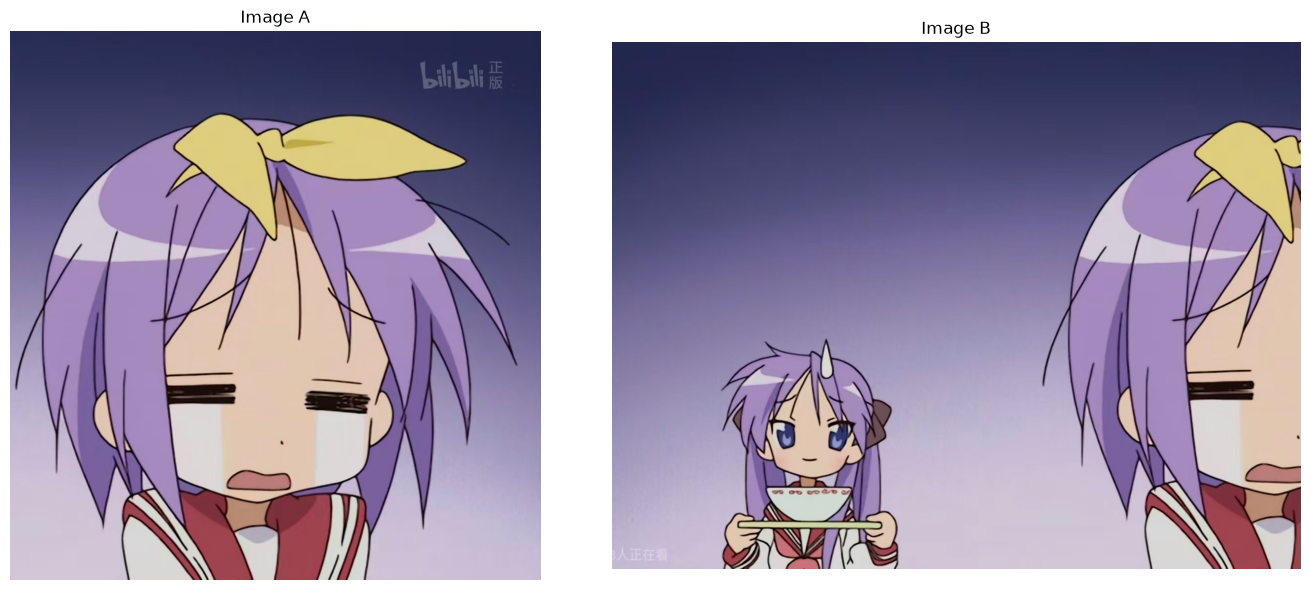

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt

print("实验目录：", EXP_DIR.name)

if img_a is None or img_b is None:
    raise FileNotFoundError("图片读取失败，请检查工作目录和文件名")

print("图像 a 的尺寸：", img_a.shape)
print("图像 b 的尺寸：", img_b.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, img, title in zip(axes, [img_a, img_b], ["Image A", "Image B"]):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()
plt.close("all")

## 2. 灰度化与 SIFT 特征提取

SIFT 在灰度图中检测局部特征，输出关键点及每个关键点的 128 维描述符。观察关键点是否集中于人物轮廓、头发和五官，平滑背景通常较少。

图像 A 的关键点数量： 847
图像 B 的关键点数量： 1151
A 的描述符形状： (847, 128)
B 的描述符形状： (1151, 128)


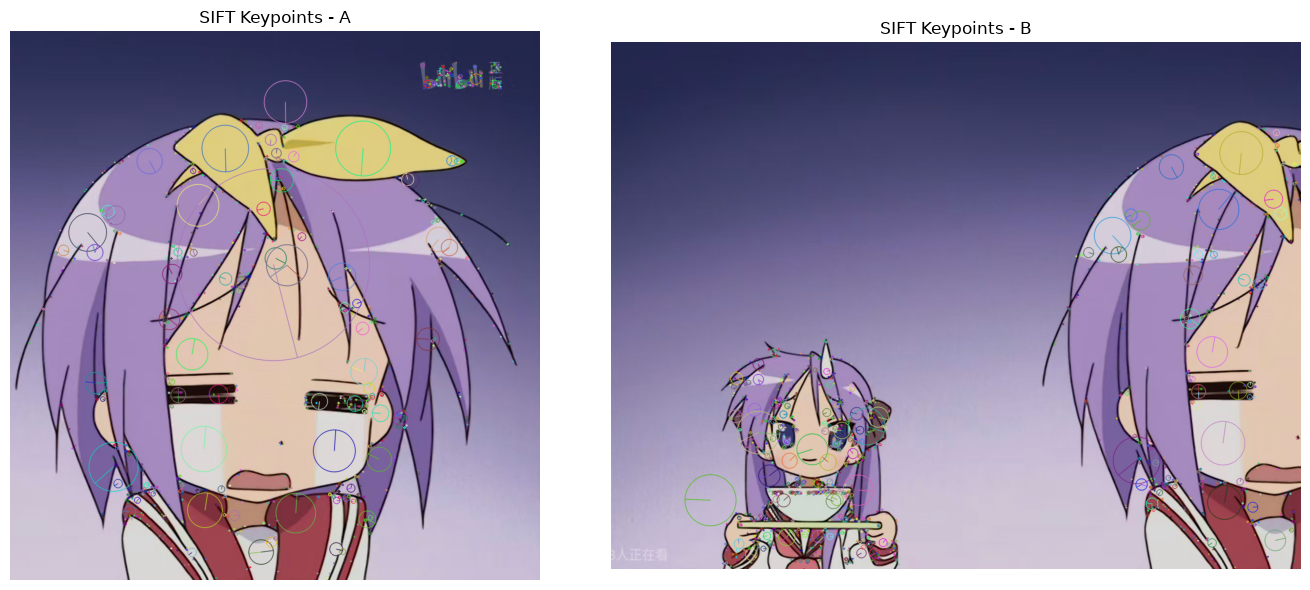

In [3]:
# 转为灰度图，用于检测特征
gray_a = cv2.cvtColor(img_a, cv2.COLOR_BGR2GRAY)
gray_b = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY)

# 检测关键点并计算描述符
sift = cv2.SIFT_create()
kp_a, des_a = sift.detectAndCompute(gray_a, None)
kp_b, des_b = sift.detectAndCompute(gray_b, None)

print("图像 A 的关键点数量：", len(kp_a))
print("图像 B 的关键点数量：", len(kp_b))
print("A 的描述符形状：", None if des_a is None else des_a.shape)
print("B 的描述符形状：", None if des_b is None else des_b.shape)

# 在原图上画出关键点
keypoints_a = cv2.drawKeypoints(
    img_a, kp_a, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
keypoints_b = cv2.drawKeypoints(
    img_b, kp_b, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, img, title in zip(
    axes,
    [keypoints_a, keypoints_b],
    ["SIFT Keypoints - A", "SIFT Keypoints - B"]
):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()
plt.close("all")

## 3. FLANN 匹配与 Lowe 比率测试

为 A 的每个描述符在 B 中找两个最近邻。如果第一候选距离小于第二候选距离的 0.7 倍，则保留。这里的距离是描述符差异，保留比例不能作为匹配准确率。

初始匹配组数： 847
筛选后匹配数量： 368
保留比例：43.45%


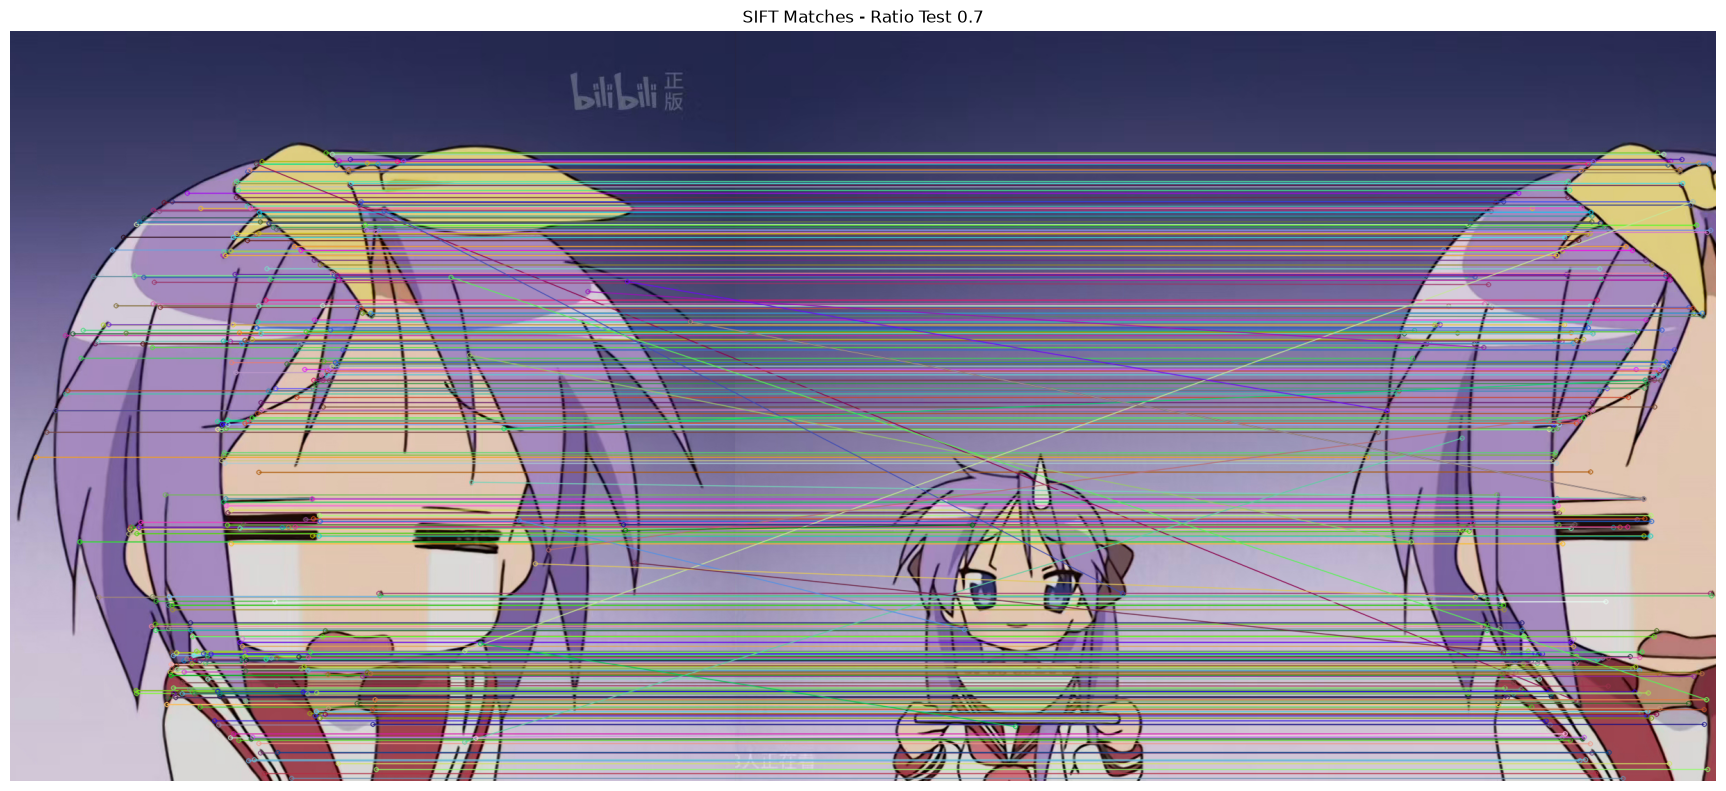

In [4]:
cv2.setRNGSeed(SEED)
# 1. 创建 FLANN 匹配器
index_params = dict(algorithm=1, trees=5)
search_params = dict(checks=50)
flann = cv2.FlannBasedMatcher(index_params, search_params)

if des_a is None or des_b is None or len(des_b) < 2:
    raise ValueError("描述符不足，无法进行匹配")

# 2. 为 A 中的每个描述符，在 B 中寻找两个最接近的候选
matches = flann.knnMatch(des_a, des_b, k=2)

# 3. 比率测试：第一候选要明显优于第二候选，才保留
good_matches = []

for pair in matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < RATIO_THRESHOLD * n.distance:
            good_matches.append(m)

print("初始匹配组数：", len(matches))
print("筛选后匹配数量：", len(good_matches))
if matches:
    print(f"保留比例：{len(good_matches) / len(matches):.2%}")

# 4. 绘制筛选后的匹配连线
matched_keypoints_img = cv2.drawMatches(
    img_a, kp_a,
    img_b, kp_b,
    good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(matched_keypoints_img, cv2.COLOR_BGR2RGB))
plt.title("SIFT Matches - Ratio Test 0.7")
plt.axis("off")
plt.tight_layout()
plt.show()
plt.close("all")

## 4. RANSAC 估计单应矩阵

匹配中的 queryIdx 属于 A、trainIdx 属于 B，因此从 B 的点映射到 A 的点，得到 H（B → A）。至少需要 4 对不退化匹配；RANSAC 使用 5 像素重投影阈值。内点比例是模型一致性指标，不是带人工真值的准确率。

参与估计的匹配数量： 368
RANSAC 内点数量： 345
内点比例：93.75%
单应矩阵 H（B → A）：
 [[ 1.00127520e+00  2.43051764e-04 -8.74402696e+02]
 [ 2.88271033e-04  1.00123262e+00 -4.99417523e-01]
 [ 5.53357464e-07  4.28705668e-07  1.00000000e+00]]


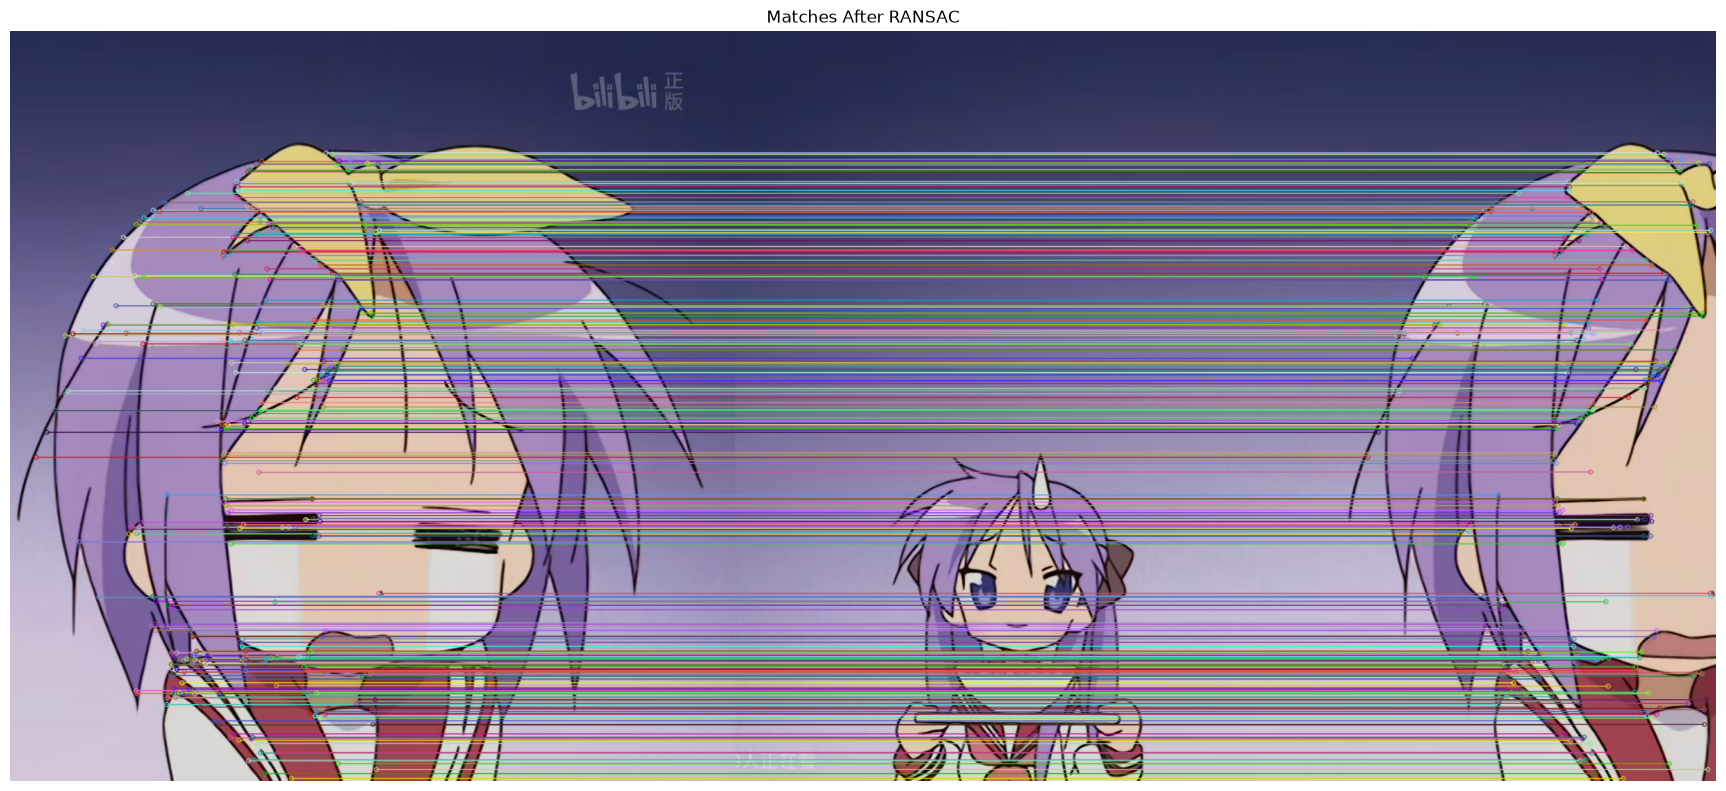

In [5]:
# 至少需要 4 对匹配点，且点的位置不能退化为共线等情况
if len(good_matches) < 4:
    raise ValueError("匹配点不足，无法估计单应矩阵")

# 将图像 B 变换到图像 A 的坐标系
src_pts = np.float32([
    kp_b[m.trainIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

dst_pts = np.float32([
    kp_a[m.queryIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

# RANSAC：允许的重投影误差阈值为 5 像素
H, mask = cv2.findHomography(
    src_pts, dst_pts, cv2.RANSAC, RANSAC_THRESHOLD
)

if H is None or mask is None or not np.isfinite(H).all():
    raise ValueError("未能得到有效的单应矩阵")

inlier_mask = mask.ravel().astype(bool)
inlier_count = int(inlier_mask.sum())
if inlier_count < 4:
    raise ValueError("RANSAC 内点不足 4 对")

print("参与估计的匹配数量：", len(good_matches))
print("RANSAC 内点数量：", inlier_count)
print(f"内点比例：{inlier_count / len(good_matches):.2%}")
print("单应矩阵 H（B → A）：\n", H)

# 只绘制 RANSAC 判定的内点匹配
inlier_matches_img = cv2.drawMatches(
    img_a, kp_a, img_b, kp_b,
    good_matches, None,
    matchesMask=inlier_mask.astype(int).tolist(),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(inlier_matches_img, cv2.COLOR_BGR2RGB))
plt.title("Matches After RANSAC")
plt.axis("off")
plt.tight_layout()
plt.show()
plt.close("all")

## 5. 透视变换并拼接

将 B 的四角通过 H 投影，与 A 的四角求共同边界；向下、向上取整并平移至非负坐标，再变换 B、用 A 覆盖重叠区域。该方法未做曝光补偿或羽化融合，亮度不同的输入可能留下接缝。

拼接结果尺寸（高、宽、通道）： (1082, 1919, 3)


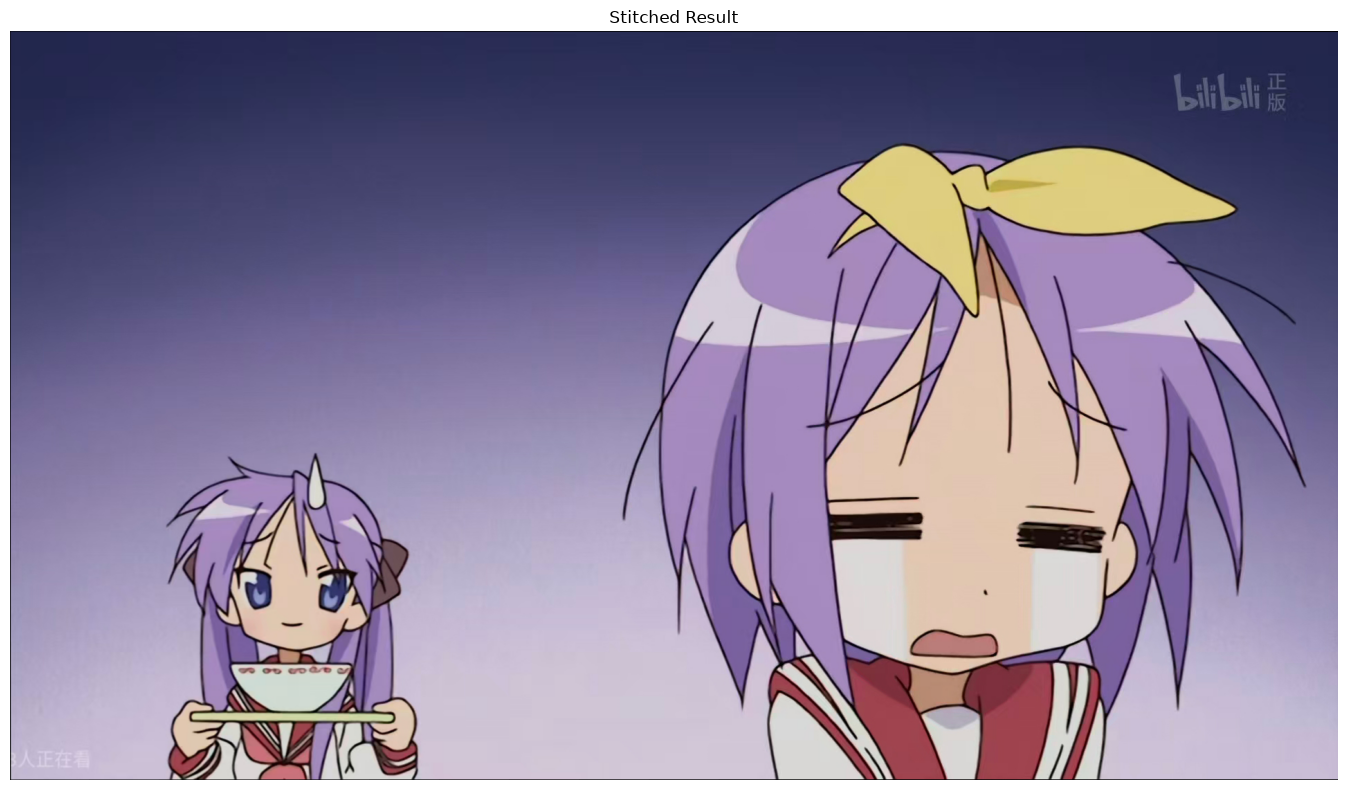

In [6]:
# 1. 获取两张图片的边界坐标
h_a, w_a = img_a.shape[:2]
h_b, w_b = img_b.shape[:2]

corners_a = np.float32([
    [0, 0], [w_a, 0], [w_a, h_a], [0, h_a]
]).reshape(-1, 1, 2)

corners_b = np.float32([
    [0, 0], [w_b, 0], [w_b, h_b], [0, h_b]
]).reshape(-1, 1, 2)

# 2. 计算 B 变换到 A 的坐标系后的边界
warped_corners_b = cv2.perspectiveTransform(corners_b, H)
all_corners = np.concatenate([corners_a, warped_corners_b])

if not np.isfinite(all_corners).all():
    raise ValueError("变换后的边界无效，请检查单应矩阵")

x_min, y_min = np.floor(
    all_corners.min(axis=0).ravel()
).astype(int)

x_max, y_max = np.ceil(
    all_corners.max(axis=0).ravel()
).astype(int)

canvas_w = int(x_max - x_min)
canvas_h = int(y_max - y_min)

# 避免错误变换产生过大的画布
if canvas_w <= 0 or canvas_h <= 0 or canvas_w * canvas_h > 30_000_000:
    raise ValueError("画布尺寸异常，请检查匹配与变换结果")

# 3. 平移到非负坐标，避免图像被画布裁掉
translation_matrix = np.array([
    [1, 0, -x_min],
    [0, 1, -y_min],
    [0, 0, 1]
], dtype=np.float64)

# 4. 将 B 放到新画布上
stitched_img = cv2.warpPerspective(
    img_b,
    translation_matrix @ H,
    (canvas_w, canvas_h)
)

# 5. 将 A 放到对应位置，覆盖重叠区域
offset_x = int(-x_min)
offset_y = int(-y_min)

stitched_img[
    offset_y:offset_y + h_a,
    offset_x:offset_x + w_a
] = img_a

print("拼接结果尺寸（高、宽、通道）：", stitched_img.shape)

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(stitched_img, cv2.COLOR_BGR2RGB))
plt.title("Stitched Result")
plt.axis("off")
plt.tight_layout()
plt.show()
plt.close("all")

## 6. 保存原亮度结果

每次新建时间戳目录。保存灰度图、关键点、两种匹配连线、拼接图和 H，保留之前的所有运行结果。

In [7]:
from pathlib import Path
from datetime import datetime

# 每次保存到新文件夹，避免覆盖已有成果
result_dir = (
    EXP_DIR / "result"
    / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
)
result_dir.mkdir(parents=True, exist_ok=False)

images = {
    "gray_a.png": gray_a,
    "gray_b.png": gray_b,
    "keypoints_a.png": keypoints_a,
    "keypoints_b.png": keypoints_b,
    "matches_ratio.png": matched_keypoints_img,
    "matches_ransac.png": inlier_matches_img,
    "stitched_result.png": stitched_img,
}

# imencode + tofile 可处理含中文的文件路径
for name, image in images.items():
    ok, encoded = cv2.imencode(".png", image)
    if not ok:
        raise RuntimeError(f"图片编码失败：{name}")
    encoded.tofile(str(result_dir / name))

np.save(result_dir / "homography.npy", H)

print("已保存到：", result_dir.relative_to(EXP_DIR))
print("保存的图片数量：", len(images))

已保存到： result\20261022-211351-749832
保存的图片数量： 7


## 7. 对照实验：将 B 的亮度缩放至 60%

A 保持不变。先使用浮点数乘法并裁剪到 [0,255]，再转回 uint8，重新提取 B 的特征。亮度缩放会降低绝对梯度幅值，可能使部分特征低于检测阈值，不能直接推断配准一定失败。

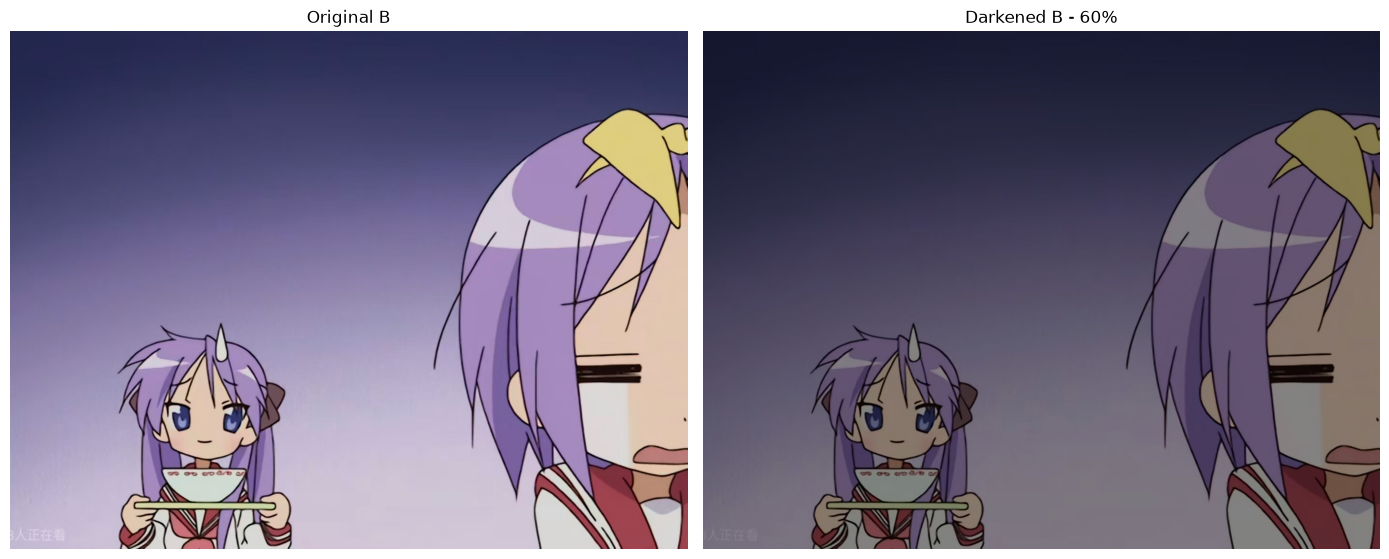

原始 B 的关键点数量： 1151
调暗 B 的关键点数量： 950


In [8]:
# 用浮点数计算，再转回 uint8，避免整数运算溢出
img_b_dark = np.clip(
    img_b.astype(np.float32) * BRIGHTNESS_FACTOR, 0, 255
).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, img, title in zip(
    axes,
    [img_b, img_b_dark],
    ["Original B", "Darkened B - 60%"]
):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()
plt.close("all")

# 在调暗后的 B 上重新提取特征
gray_b_dark = cv2.cvtColor(img_b_dark, cv2.COLOR_BGR2GRAY)
kp_b_dark, des_b_dark = sift.detectAndCompute(gray_b_dark, None)

print("原始 B 的关键点数量：", len(kp_b))
print("调暗 B 的关键点数量：", len(kp_b_dark))

## 8. 重新匹配、估计变换并比较拼接结果

对调暗的 B 重新匹配与估计 H，不沿用原亮度的 H。比较人物是否对齐，以及背景有无明显明暗分界，区分几何配准与亮度融合。

调暗后筛选匹配数量： 290
调暗后 RANSAC 内点数量： 268
内点比例：92.41%


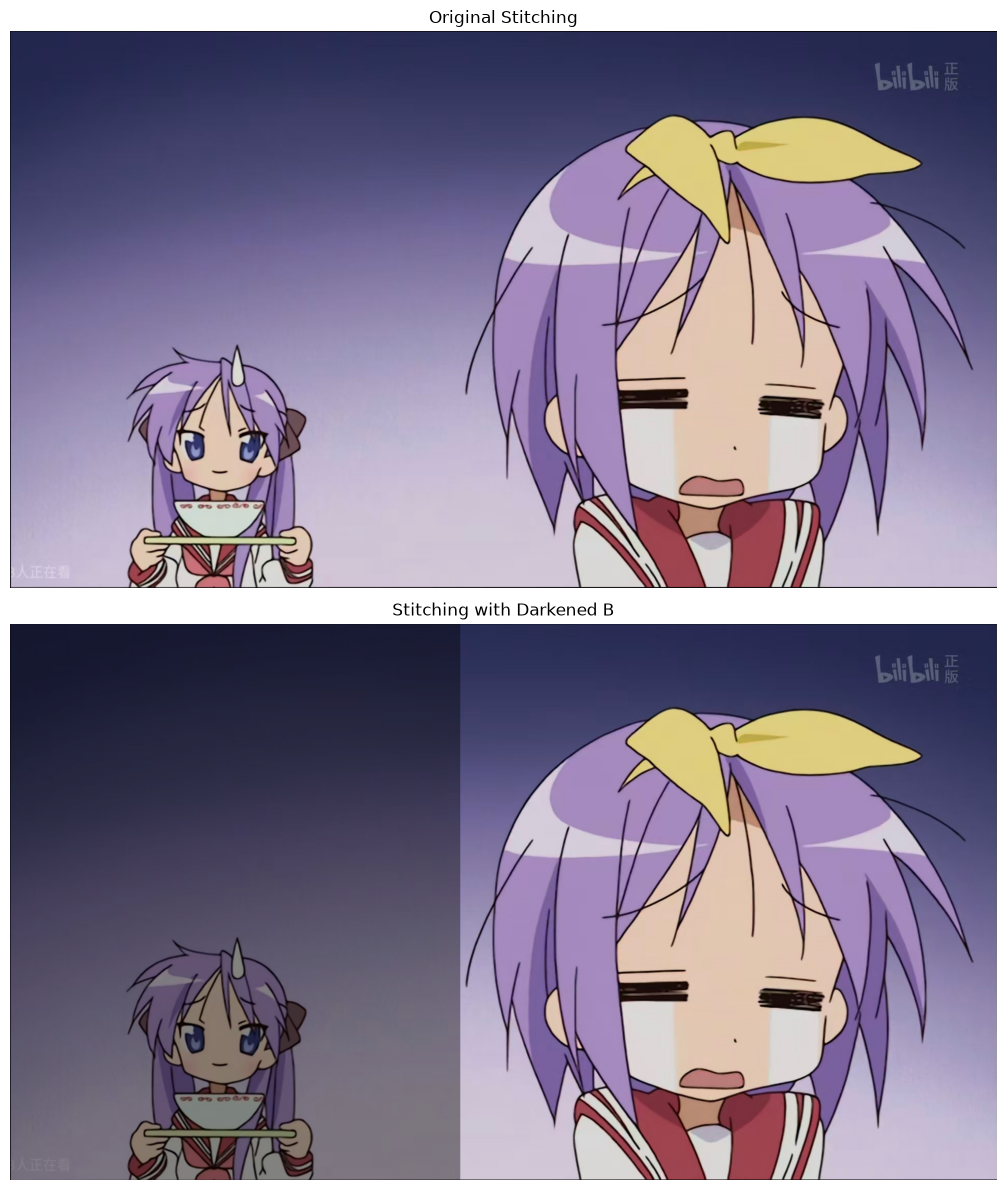

In [9]:
cv2.setRNGSeed(SEED)
# 1. 重新匹配：A 不变，B 使用调暗后的描述符
if des_b_dark is None or len(des_b_dark) < 2:
    raise ValueError("调暗后的 B 特征不足")

matches_dark = flann.knnMatch(des_a, des_b_dark, k=2)

good_dark = []
for pair in matches_dark:
    if len(pair) == 2:
        m, n = pair
        if m.distance < RATIO_THRESHOLD * n.distance:
            good_dark.append(m)

if len(good_dark) < 4:
    raise ValueError("筛选后匹配不足 4 对，无法估计变换")

# 2. 重新估计 B → A 的单应矩阵
src_dark = np.float32([
    kp_b_dark[m.trainIdx].pt for m in good_dark
]).reshape(-1, 1, 2)

dst_dark = np.float32([
    kp_a[m.queryIdx].pt for m in good_dark
]).reshape(-1, 1, 2)

H_dark, mask_dark = cv2.findHomography(
    src_dark, dst_dark, cv2.RANSAC, RANSAC_THRESHOLD
)

if H_dark is None or mask_dark is None:
    raise ValueError("单应矩阵估计失败")

if not np.isfinite(H_dark).all() or mask_dark.sum() < 4:
    raise ValueError("变换矩阵或内点数量异常")

print("调暗后筛选匹配数量：", len(good_dark))
print("调暗后 RANSAC 内点数量：", int(mask_dark.sum()))
print(f"内点比例：{mask_dark.sum() / len(good_dark):.2%}")

# 3. 根据新矩阵计算画布范围
warped_corners_dark = cv2.perspectiveTransform(corners_b, H_dark)
all_corners_dark = np.concatenate([
    corners_a, warped_corners_dark
])

if not np.isfinite(all_corners_dark).all():
    raise ValueError("变换后的边界异常")

xmin_d, ymin_d = np.floor(
    all_corners_dark.min(axis=0).ravel()
).astype(int)

xmax_d, ymax_d = np.ceil(
    all_corners_dark.max(axis=0).ravel()
).astype(int)

width_d = int(xmax_d - xmin_d)
height_d = int(ymax_d - ymin_d)

if width_d <= 0 or height_d <= 0 or width_d * height_d > 30_000_000:
    raise ValueError("画布尺寸异常")

T_dark = np.array([
    [1, 0, -xmin_d],
    [0, 1, -ymin_d],
    [0, 0, 1]
], dtype=np.float64)

# 4. 变换调暗后的 B，再用原亮度 A 覆盖对应区域
stitched_dark = cv2.warpPerspective(
    img_b_dark, T_dark @ H_dark, (width_d, height_d)
)

ox_d, oy_d = int(-xmin_d), int(-ymin_d)
stitched_dark[
    oy_d:oy_d + h_a,
    ox_d:ox_d + w_a
] = img_a

# 5. 与正常亮度拼接结果对比
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

for ax, img, title in zip(
    axes,
    [stitched_img, stitched_dark],
    ["Original Stitching", "Stitching with Darkened B"]
):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()
plt.close("all")

## 9. 保存亮度对照结果

亮度对照保存在本次结果目录的独立子目录中，不覆盖原亮度结果。

In [10]:
# 使用前面创建的 result_dir
dark_result_dir = result_dir / (
    "brightness_" + datetime.now().strftime("%H%M%S-%f")
)
dark_result_dir.mkdir(parents=True, exist_ok=False)

for name, image in {
    "b_dark.png": img_b_dark,
    "stitched_dark.png": stitched_dark,
}.items():
    ok, encoded = cv2.imencode(".png", image)
    if not ok:
        raise RuntimeError(f"图片编码失败：{name}")
    encoded.tofile(str(dark_result_dir / name))

print("已保存到：", dark_result_dir.relative_to(EXP_DIR))

已保存到： result\20261022-211351-749832\brightness_211354-346362


## 10. 汇总实测数据与生成报告插图

重投影误差只对 RANSAC 内点计算：将 B 的内点通过 H 映射到 A，再计算欧氏距离。
该指标描述样本点的几何拟合程度，不能代替整幅图的视觉检查。
此处把本次参数、版本、输入哈希、匹配统计和误差写入 JSON，方便复核报告。
仓库中的报告引用整理时已验证的那一次结果；再次运行会创建新目录，不自动改写历史报告。

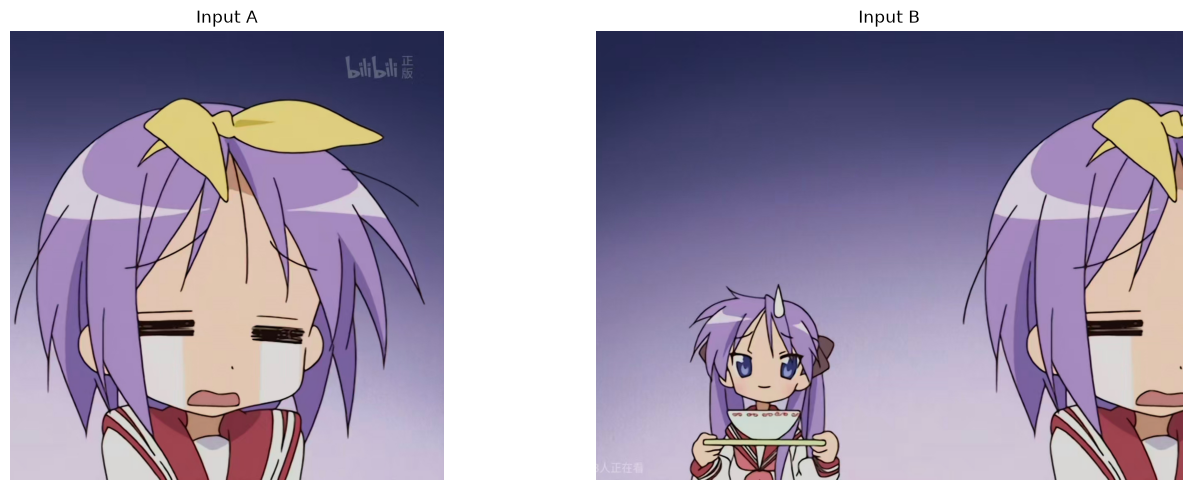

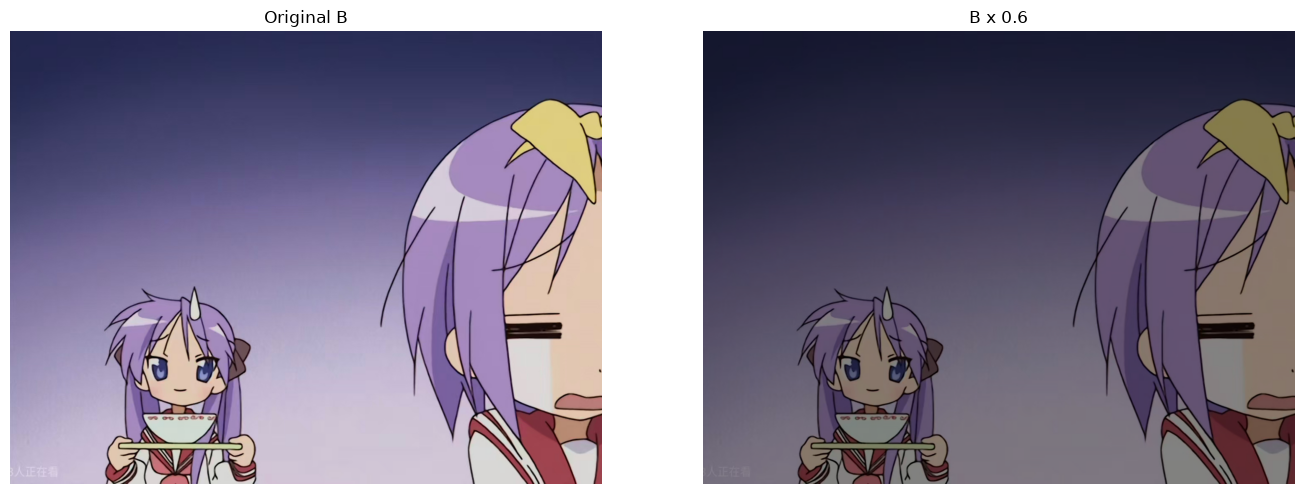

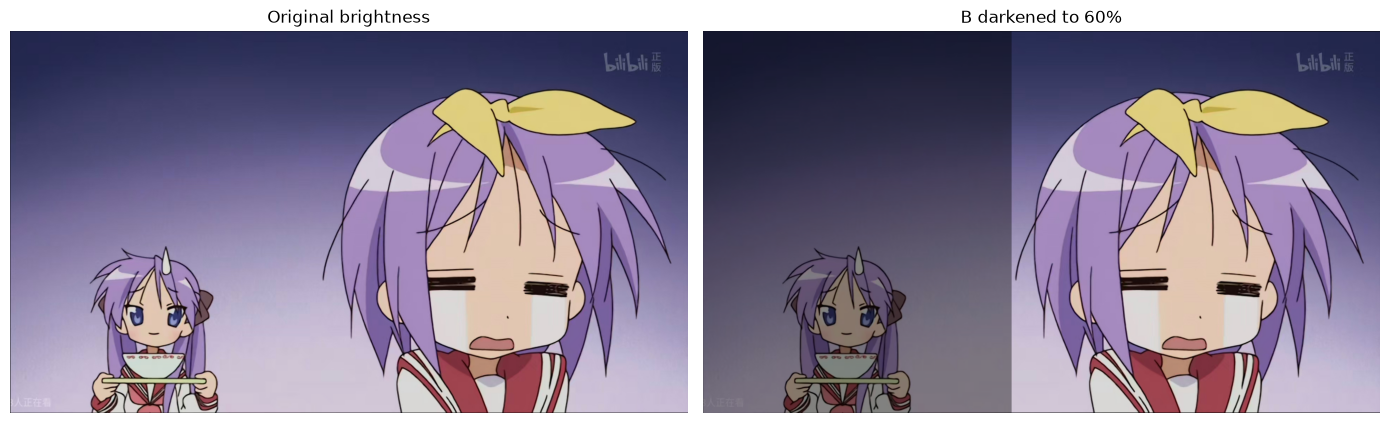

| 指标 | 原亮度 | B 调暗至 60% |
|---|---:|---:|
| A 关键点 | 847 | 847 |
| B 关键点 | 1151 | 950 |
| 初始匹配组数 | 847 | 847 |
| 比率测试保留匹配数 | 368 | 290 |
| RANSAC 内点数 | 345 | 268 |
| 比率测试保留比例 | 43.45% | 34.24% |
| RANSAC 内点比例 | 93.75% | 92.41% |
| 内点平均重投影误差 / px | 0.1188 | 0.1526 |
| 内点中位重投影误差 / px | 0.0522 | 0.0744 |


结果与统计均已保存： result\20261022-211351-749832


In [11]:
def geometry_stats(src, dst, matrix, mask):
    predicted = cv2.perspectiveTransform(src, matrix)
    errors = np.linalg.norm(predicted - dst, axis=2).ravel()
    kept = errors[mask.ravel().astype(bool)]
    return {'mean_inlier_error_px': float(kept.mean()),
            'median_inlier_error_px': float(np.median(kept)),
            'max_inlier_error_px': float(kept.max())}

def case_stats(keypoints_b, candidate_matches, good, mask, matrix, stitched, src, dst):
    return {'keypoints_a': len(kp_a), 'keypoints_b': len(keypoints_b),
            'candidate_matches': len(candidate_matches), 'ratio_matches': len(good),
            'retention_ratio': len(good) / len(candidate_matches),
            'inliers': int(mask.sum()), 'inlier_ratio': float(mask.sum() / len(good)),
            'stitched_shape_hwc': list(stitched.shape), 'homography_b_to_a': matrix.tolist(),
            **geometry_stats(src, dst, matrix, mask)}

metrics = {
    'experiment': 'SIFT + FLANN + RANSAC image stitching',
    'run_directory': result_dir.relative_to(EXP_DIR).as_posix(),
    'brightness_directory': dark_result_dir.relative_to(EXP_DIR).as_posix(),
    'versions': {'python': platform.python_version(), 'opencv': cv2.__version__,
                 'numpy': np.__version__, 'matplotlib': matplotlib.__version__},
    'parameters': {'seed': SEED, 'opencv_threads': 1, 'ratio_threshold': RATIO_THRESHOLD,
                   'ransac_reprojection_threshold_px': RANSAC_THRESHOLD,
                   'brightness_factor': BRIGHTNESS_FACTOR,
                   'flann_trees': 5, 'flann_checks': 50},
    'inputs': {name: {'sha256': hashlib.sha256((EXP_DIR / 'img' / name).read_bytes()).hexdigest(),
                      'shape_hwc': list(image.shape)}
               for name, image in [('a.jpg', img_a), ('b.jpg', img_b)]},
    'original': case_stats(kp_b, matches, good_matches, mask, H, stitched_img, src_pts, dst_pts),
    'darkened': case_stats(kp_b_dark, matches_dark, good_dark, mask_dark, H_dark,
                           stitched_dark, src_dark, dst_dark),
}

def save_png(path, image):
    ok, data = cv2.imencode('.png', image)
    if not ok:
        raise RuntimeError(f'图像编码失败：{path.name}')
    data.tofile(str(path))

dark_matches_img = cv2.drawMatches(
    img_a, kp_a, img_b_dark, kp_b_dark, good_dark, None,
    matchesMask=mask_dark.ravel().astype(int).tolist(),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
save_png(dark_result_dir / 'matches_ransac_dark.png', dark_matches_img)
np.save(dark_result_dir / 'homography_dark.npy', H_dark)

for filename, images_to_show, titles in [
    ('inputs_comparison.png', [img_a, img_b], ['Input A', 'Input B']),
    ('brightness_comparison.png', [img_b, img_b_dark], ['Original B', 'B x 0.6']),
    ('stitching_comparison.png', [stitched_img, stitched_dark],
     ['Original brightness', 'B darkened to 60%'])
]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, image, title in zip(axes, images_to_show, titles):
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(result_dir / filename, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)

table = '| 指标 | 原亮度 | B 调暗至 60% |\n|---|---:|---:|\n'
for label, key in [('A 关键点', 'keypoints_a'), ('B 关键点', 'keypoints_b'),
                   ('初始匹配组数', 'candidate_matches'), ('比率测试保留匹配数', 'ratio_matches'),
                   ('RANSAC 内点数', 'inliers')]:
    table += f"| {label} | {metrics['original'][key]} | {metrics['darkened'][key]} |\n"
for label, key in [('比率测试保留比例', 'retention_ratio'), ('RANSAC 内点比例', 'inlier_ratio')]:
    table += f"| {label} | {metrics['original'][key]:.2%} | {metrics['darkened'][key]:.2%} |\n"
for label, key in [('内点平均重投影误差 / px', 'mean_inlier_error_px'),
                   ('内点中位重投影误差 / px', 'median_inlier_error_px')]:
    table += f"| {label} | {metrics['original'][key]:.4f} | {metrics['darkened'][key]:.4f} |\n"
display(Markdown(table))
(result_dir / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
(result_dir / 'metrics_table.md').write_text(table, encoding='utf-8')
print('结果与统计均已保存：', result_dir.relative_to(EXP_DIR))

## 11. 结果分析与实验思考

1. 结合关键点图，解释人物的头发、轮廓、五官比平滑背景更容易产生特征的原因。
2. 比率测试是在描述符空间消除歧义，RANSAC 则检验几何一致性，二者不能互相替代。
3. 比较原亮度与调暗后的关键点数量、匹配数、内点比例及重投影误差。不要把内点比例直接称为准确率。
4. 观察两幅拼接结果：人物基本对齐时仍可能有亮度接缝，说明配准与融合是不同问题。
5. 当前使用 A 覆盖重叠区域，可进一步尝试曝光补偿、羽化或多频段融合；本次未将这些改进计入已完成内容。

详细记录见同目录的 `实验报告.md`。指导截图仅作为整理依据，不作为执行指令；截图中的历史数值与本次实测数值区分记录。